# Customer Churn: Modeling

In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score
import joblib
import os

plt.style.use("default")   # white background for saved charts

In [41]:
df = pd.read_csv("../data/churn_clean.csv")
df.shape

(7043, 20)

In [42]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup","DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)
df.groupby("num_services")["Churn"].mean().round(3)

num_services
0    0.438
1    0.211
2    0.328
3    0.365
4    0.313
5    0.256
6    0.225
7    0.124
8    0.053
Name: Churn, dtype: float64

In [43]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(f"Churn rate - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

(5634, 20) (1409, 20)
Churn rate - train: 0.265, test: 0.265


In [45]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
cat_cols = [col for col in X.columns if col not in num_cols]

print(len(num_cols), "number columns")
print(len(cat_cols), "category columns:", cat_cols)

4 number columns
16 category columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [46]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
X_train_ready = preprocessor.fit_transform(X_train)
X_train_ready.shape

(5634, 47)

## Preparing the data

- **New feature:** `num_services`, the number of services each customer has (0–8).
- **Train/test split:** 80% train / 20% test, stratified so both keep the 26.5% churn rate.
  The test set stays untouched until final evaluation.
- **Preprocessing:** one-hot encoding for 16 category columns, standard scaling for
  4 number columns → 47 features.
- **No data leakage:** the preprocessor is fitted on the **training data only**. If it
  learned the scaling (mean/std) from the test set too, information from the
  "exam" would leak into training and make the scores look better than they really are.

In [47]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

In [48]:
results = {}

def evaluate(name, model):
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=True)
    results[name] = {m: round(scores[f"test_{m}"].mean(), 3) for m in scoring}
    results[name]["train_roc_auc"] = round(scores["train_roc_auc"].mean(), 3)
    return pd.DataFrame(results).T

In [49]:
evaluate("Baseline (always 'stay')", DummyClassifier(strategy="most_frequent"))

/Users/os_bhosale/Desktop/Data Science Projects/Customer-Churn-Prediction/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/os_bhosale/Desktop/Data Science Projects/Customer-Churn-Prediction/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/os_bhosale/Desktop/Data Science Projects/Customer-Churn-Prediction/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predic

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.0,0.0,0.0,0.5,0.5


In [50]:
evaluate("Logistic Regression", LogisticRegression(max_iter=1000))

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.50
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.85


In [51]:
evaluate("Logistic Regression (balanced)",
         LogisticRegression(max_iter=1000, class_weight="balanced"))

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.50
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.85
Logistic Regression (balanced),0.748,0.517,0.801,0.628,0.846,0.85


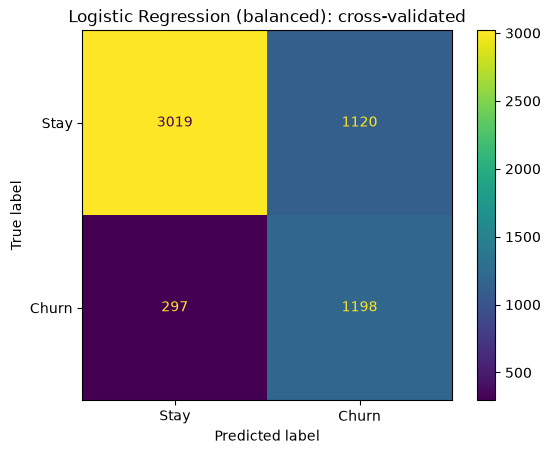

In [52]:
balanced_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
y_pred = cross_val_predict(balanced_pipe, X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(y_train, y_pred,
                                        display_labels=["Stay", "Churn"])
plt.title("Logistic Regression (balanced): cross-validated")
plt.savefig("../images/confusion_matrix_logreg.png", dpi=150, bbox_inches="tight")
plt.show()

## Model results (5-fold cross-validation on training data)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (always "stay") | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression | 0.802 | 0.653 | 0.543 | 0.592 | 0.846 |
| Logistic Regression (balanced) | 0.748 | 0.517 | 0.801 | 0.628 | 0.846 |

- The baseline gets **73.5% accuracy while catching zero churners**, which proves accuracy is misleading here.
- Logistic regression is much better (ROC-AUC 0.846) but only catches **54%** of churners.
- With `class_weight="balanced"`, recall rises to **80%** (1,198 of 1,495 churners caught),
  at the cost of more false alarms (precision 52%).
- **For churn, recall matters more:** a missed churner loses ~$80/month,
  while a false alarm only costs a retention offer. So the balanced model is the better choice.
- Next: try tree-based models (Random Forest, XGBoost) to see if they can beat ROC-AUC 0.846.

In [53]:
evaluate("Random Forest (default)", RandomForestClassifier(random_state=42))

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.50
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.85
Logistic Regression (balanced),0.748,0.517,0.801,0.628,0.846,0.85
Random Forest (default),0.786,0.628,0.482,0.545,0.820,1.00


In [54]:
evaluate("Random Forest (tuned)",
         RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                class_weight="balanced", random_state=42))

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.500
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.850
Logistic Regression (balanced),0.748,0.517,0.801,0.628,0.846,0.850
Random Forest (default),0.786,0.628,0.482,0.545,0.820,1.000
Random Forest (tuned),0.759,0.532,0.782,0.633,0.847,0.902


In [55]:
evaluate("XGBoost (default)", XGBClassifier(random_state=42))

,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.500
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.850
Logistic Regression (balanced),0.748,0.517,0.801,0.628,0.846,0.850
Random Forest (default),0.786,0.628,0.482,0.545,0.820,1.000
Random Forest (tuned),0.759,0.532,0.782,0.633,0.847,0.902
XGBoost (default),0.780,0.603,0.506,0.549,0.825,0.991


In [56]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {ratio:.2f}")

evaluate("XGBoost (tuned)",
         XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                       scale_pos_weight=ratio, random_state=42))

scale_pos_weight = 2.77


,accuracy,precision,recall,f1,roc_auc,train_roc_auc
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500,0.500
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.850
Logistic Regression (balanced),0.748,0.517,0.801,0.628,0.846,0.850
Random Forest (default),0.786,0.628,0.482,0.545,0.820,1.000
Random Forest (tuned),0.759,0.532,0.782,0.633,0.847,0.902
XGBoost (default),0.780,0.603,0.506,0.549,0.825,0.991
XGBoost (tuned),0.754,0.524,0.797,0.632,0.846,0.889


## Tree models vs logistic regression

- **Default Random Forest and XGBoost overfit badly:** train ROC-AUC of 1.000 and 0.991,
  but only 0.820 and 0.825 on cross-validation. They memorized the training customers.
- **Controlling tree size** (`min_samples_leaf`, `max_depth`, small `learning_rate`) plus
  class balancing fixed it: both reached ~0.846 ROC-AUC with ~0.79 recall.
- **But they did not beat logistic regression** (0.846 ROC-AUC, 0.801 recall).
  This dataset's patterns are fairly simple (contract, tenure, internet type), so a
  linear model captures them well.

**Final model: Logistic Regression (balanced).** Same performance as the tree models,
the best recall, and much simpler to explain and run. When models tie,
choose the simpler one.

In [57]:
final_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

cv_proba = cross_val_predict(final_pipe, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]
cv_proba[:5].round(2)

array([0.64, 0.53, 0.09, 0.21, 0.62])

In [58]:
OFFER_COST = 50      # $ per contacted customer (discount + call)
SUCCESS_RATE = 0.30  # share of contacted churners who decide to stay
MONTHS_KEPT = 12     # a saved customer stays 12 more months

def profit(y_true, proba, charges, threshold):
    flagged = proba >= threshold
    caught = flagged & (y_true == 1)
    saved_revenue = SUCCESS_RATE * MONTHS_KEPT * charges[caught].sum()
    cost = OFFER_COST * flagged.sum()
    return saved_revenue - cost

In [59]:
y_train_arr = y_train.to_numpy()
charges_train = X_train["MonthlyCharges"].to_numpy()

rows = []
for t in np.arange(0.05, 0.96, 0.05).round(2):
    flagged = cv_proba >= t
    rows.append({
        "threshold": t,
        "flagged": flagged.sum(),
        "recall": recall_score(y_train_arr, flagged),
        "precision": precision_score(y_train_arr, flagged, zero_division=0),
        "profit": profit(y_train_arr, cv_proba, charges_train, t),
    })

threshold_table = pd.DataFrame(rows).round(3)
best_threshold = threshold_table.loc[threshold_table["profit"].idxmax(), "threshold"]
print("Best threshold:", best_threshold)
threshold_table

Best threshold: 0.4


,threshold,flagged,recall,precision,profit
0,0.05,4826,0.991,0.307,159364.52
1,0.10,4352,0.982,0.337,179903.54
2,0.15,3985,0.971,0.364,194139.82
3,0.20,3699,0.955,0.386,201872.16
4,0.25,3477,0.940,0.404,207408.18
5,0.30,3264,0.927,0.425,212846.10
6,0.35,3025,0.902,0.446,217910.38
7,0.40,2751,0.866,0.471,221082.00
8,0.45,2536,0.833,0.491,220201.84
9,0.50,2318,0.801,0.517,220639.16


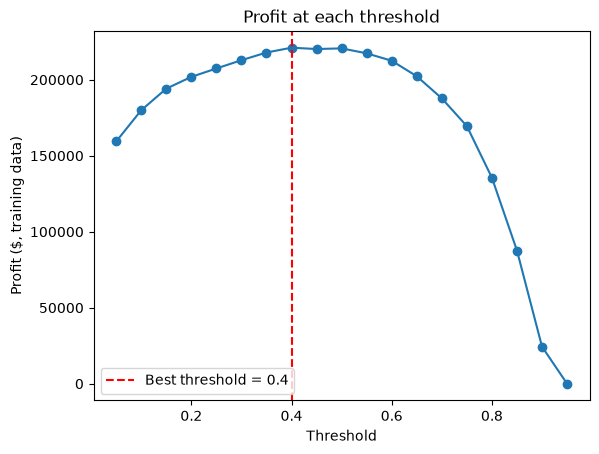

In [60]:
plt.plot(threshold_table["threshold"], threshold_table["profit"], marker="o")
plt.axvline(best_threshold, color="red", linestyle="--",
            label=f"Best threshold = {best_threshold}")
plt.xlabel("Threshold")
plt.ylabel("Profit ($, training data)")
plt.title("Profit at each threshold")
plt.legend()
plt.savefig("../images/profit_by_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [61]:
final_pipe.fit(X_train, y_train)
test_proba = final_pipe.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}")

Test ROC-AUC: 0.842


Recall:    0.866
Precision: 0.466
F1:        0.606


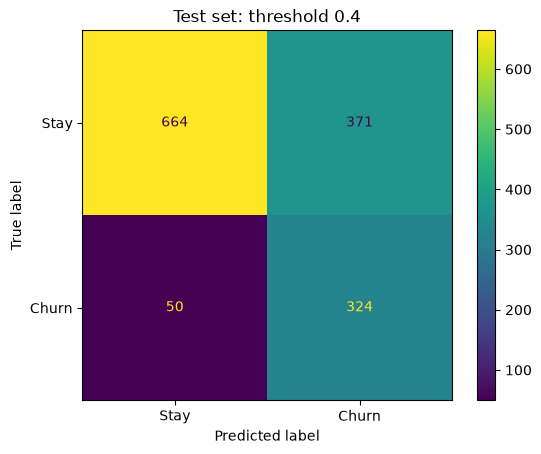

In [62]:
test_pred = (test_proba >= best_threshold).astype(int)

print(f"Recall:    {recall_score(y_test, test_pred):.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"F1:        {f1_score(y_test, test_pred):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
                                        display_labels=["Stay", "Churn"])
plt.title(f"Test set: threshold {best_threshold}")
plt.savefig("../images/confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [63]:
y_test_arr = y_test.to_numpy()
charges_test = X_test["MonthlyCharges"].to_numpy()

strategies = {
    "Do nothing": 0,
    "Contact everyone": profit(y_test_arr, np.ones(len(y_test_arr)), charges_test, 0.5),
    f"Our model (threshold {best_threshold})": profit(y_test_arr, test_proba, charges_test, best_threshold),
    "Perfect model (impossible)": profit(y_test_arr, y_test_arr.astype(float), charges_test, 0.5),
}
money = pd.Series(strategies).round(0)
print(money)

model_profit = strategies[f"Our model (threshold {best_threshold})"]
print(f"\nTest set = {len(y_test)} customers (20% of the company)")
print(f"Estimated yearly profit for all customers: ${model_profit * 5:,.0f}")

Do nothing                        0.0
Contact everyone              27524.0
Our model (threshold 0.4)     52010.0
Perfect model (impossible)    79274.0
dtype: float64

Test set = 1409 customers (20% of the company)
Estimated yearly profit for all customers: $260,048


In [64]:
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": final_pipe, "threshold": best_threshold},
            "../models/churn_model.joblib")
print("Saved!")

Saved!


## Final results on the test set

**Choosing the threshold (on training data, with cross-validation):**
Assumptions: a retention offer costs **$50**, **30%** of contacted churners stay,
and a saved customer stays **12 months**. Under these assumptions, the most
profitable threshold is **0.40** (not the default 0.5).

**Test set (1,409 customers the model never saw):**
- ROC-AUC **0.842** (vs 0.846 in cross-validation, so no overfitting)
- At threshold 0.40: **recall 86.6%** (324 of 374 churners caught), precision 46.6%

**Business value (test set):**

| Strategy | Profit |
|---|---|
| Do nothing | $0 |
| Contact everyone | $27,524 |
| **Our model** | **$52,010** |
| Perfect model (upper limit) | $79,274 |

The model earns almost **2× more than contacting everyone** and captures **66%**
of the maximum possible profit. Scaled to the whole customer base, that is roughly
**$260K per year**.

**Note:** the best threshold depends on the assumptions. With a $100 offer,
it moves up to about 0.65 (contact fewer, more certain customers).